# The double slit

A particle passes a wall with two slits and is detected on a screen behind it. Each particle arrives
at a single spot, but many of them build up interference fringes, as if each had gone through both
slits. Feynman called this "the only mystery" of quantum mechanics (*Feynman Lectures* III, ch. 1).
It was shown with single electrons by Tonomura et al., Am. J. Phys. **57**, 117 (1989), and with
molecules as large as C₆₀ by Arndt et al., Nature **401**, 680 (1999).

This notebook sends a wavepacket through a double slit in two dimensions, records the pattern on a
screen with `so.analyzers.IntegratedDensity`, compares it with the Huygens–Fresnel and Fraunhofer
predictions, and closes one slit at a time to show that the probabilities of the two paths do not
add up.

In [1]:
# On Colab or JupyterLite (or anywhere without the package), install it first:
try:
    import so_schroedinger  # noqa: F401
except ImportError:
    import sys

    if sys.platform == "emscripten":  # JupyterLite: the package comes with the site
        %pip install so_schroedinger
    else:
        %pip install -q git+https://github.com/aeberspaecher/splitoperator

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72
plt.rcParams["animation.embed_limit"] = 50  # MB

## The wall

The library has no slit potential, but any class with a method `V(r, t)` will do. The wall is a strip
of thickness $0.5$ at $x = 0$ with height $V_0$ far above the kinetic energy; each slit is a gap of
width $a$ centered at $y_c$. The edges are smoothed with $\tanh$ over a width $w$ to keep momenta on
the grid bounded.

dx = 0.156, 6.4 points per wavelength


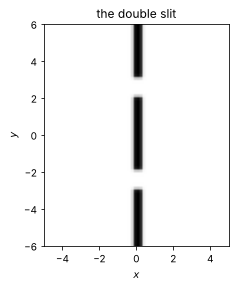

In [3]:
class Slits(so.Potential2d):
    """A wall at x = 0 with gaps of width a centered at the given y values."""

    is_time_dependent = False

    def __init__(self, centers, a, thickness=0.5, V0=100.0, w=0.08):
        self.centers, self.a, self.thickness, self.V0, self.w = centers, a, thickness, V0, w

    def V(self, r, t):
        x, y = r
        step = lambda d: 0.5 * (1 + np.tanh(d / self.w))  # 0 for d < 0, 1 for d > 0
        wall = step(self.thickness / 2 - np.abs(x))
        for yc in self.centers:
            wall = wall * step(np.abs(y - yc) - self.a / 2)
        return self.V0 * wall + 0.0j


wavelength = 1.0
k = 2 * np.pi / wavelength  # kinetic energy k^2/2 ~ 20 << V0
d, a = 5.0, 1.0  # slit distance and width
both = Slits([-d / 2, d / 2], a)

size = ((-30.0, 66.0), (-40.0, 40.0))
N = (614, 512)
absorber = so.BoundaryAbsorber2d(size, width=12.0, strength=2.0)
psi0 = so.Gaussian2d(x0=-12.0, y0=0.0, sigma_x=4.0, sigma_y=12.0, px=k)
grid = so.Grid2d(size, N, both, psi0, absorber=absorber)

so.plotting.plot2d(grid, np.real(grid.V), kind="real", cmap="Greys")
plt.xlim(-5, 5)
plt.ylim(-6, 6)
plt.title("the double slit")
print(f"dx = {grid.dx:.3f}, {wavelength / grid.dx:.1f} points per wavelength")

## A wavepacket passes the slits

The packet is broad in $y$, so it illuminates both slits about equally, and long in $x$, so its
momentum spread is small and the fringes are sharp. Most of it is reflected by the wall. Behind the
slits, the two circular waves overlap and interfere. The absorbing layer at the edges swallows what
leaves the box; it is wide and weak, because a sharp absorber reflects part of the wave back, and
the reflection adds fine ripples to the pattern on the screen.

In [4]:
dt = 0.02
anim = so.animate2d(grid, so.SplitOperator(), dt, n_frames=50, steps_per_frame=15, potential_levels=[50.0], vmax=4e-4)
HTML(anim.to_jshtml())

## The pattern on the screen

The screen is the line $x = L$. What a detector there counts over the whole run is the time
integral of the density, $\int |\psi(L, y, t)|^2\,\mathrm{d}t$, which `IntegratedDensity` accumulates
during the propagation. `Flux(position=2.0)` measures the probability that passes the line just
behind the wall, i.e. the total transmission through the slits.

transmitted through the slits: 0.0913


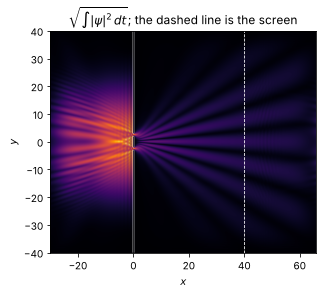

In [5]:
L = 40.0
i_screen = np.argmin(np.abs(grid.x_vals - L))
y = grid.y_vals


def run(potential, t_max=15.0):
    grid = so.Grid2d(size, N, potential, psi0, absorber=absorber)
    density, flux = so.analyzers.IntegratedDensity(), so.analyzers.Flux(2.0)
    density(grid)
    flux(grid)
    so.SplitOperator().propagate(grid, dt, int(t_max / dt), callback=[density, flux], every=2)
    return grid, density.density, flux.transferred


grid, rho, T_both = run(both)
screen = rho[i_screen]

so.plotting.plot2d(grid, np.sqrt(rho), kind="real", cmap="inferno", potential_levels=[50.0])
plt.axvline(L, color="w", ls="--", lw=0.8)
plt.title(r"$\sqrt{\int |\psi|^2\,dt}$; the dashed line is the screen")
print(f"transmitted through the slits: {T_both:.4f}")

Far from the slits (Fraunhofer limit, $L \gg d^2/\lambda$), a wave leaving the slits at angle $\theta$
picks up a path difference $d\sin\theta$ between the two slits and $a\sin\theta$ across each slit,
which gives

$$I(\theta) \propto \cos^2\!\left(\frac{\pi d\sin\theta}{\lambda}\right)\,
\mathrm{sinc}^2\!\left(\frac{a\sin\theta}{\lambda}\right),$$

with bright fringes at $\sin\theta = n\lambda/d$, i.e. about $\lambda L/d$ apart on the screen. Here
$L = 40$ is only $1.6\,d^2/\lambda$, so we also sum Huygens wavelets from each point $y'$ of the two
openings: in two dimensions, a wavelet at distance $r$ is $e^{ikr}/\sqrt{r}$, times the obliquity
factor $L/r$.

fringe distance lambda L / d = 8.0


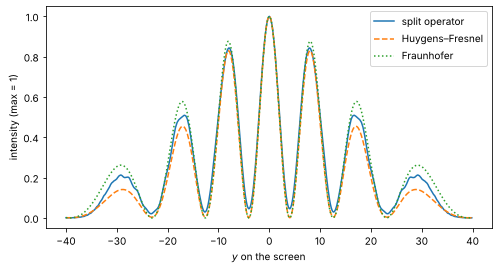

In [6]:
theta = np.arctan(y / L)
s = np.sin(theta)
fraunhofer = np.cos(np.pi * d * s / wavelength) ** 2 * np.sinc(a * s / wavelength) ** 2

y_open = np.concatenate([np.linspace(yc - a / 2, yc + a / 2, 200) for yc in (-d / 2, d / 2)])
r = np.hypot(L, y[:, None] - y_open[None, :])
huygens = np.abs(np.sum(np.exp(1j * k * r) / np.sqrt(r) * L / r, axis=1)) ** 2

plt.plot(y, screen / screen.max(), label="split operator")
plt.plot(y, huygens / huygens.max(), "--", label="Huygens–Fresnel")
plt.plot(y, fraunhofer / fraunhofer.max(), ":", label="Fraunhofer")
plt.xlabel("$y$ on the screen")
plt.ylabel("intensity (max = 1)")
plt.legend()
print(f"fringe distance lambda L / d = {wavelength * L / d:.1f}")

Both predictions get the fringe positions right. The heights of the outer fringes lie between
the two: the Fraunhofer curve ignores that the outer fringes are farther away and seen under a
larger angle, and neither formula is exact for openings as narrow as a wavelength in a wall of
finite thickness. The minima are not quite empty, partly because the packet has a spread of
momenta, and each momentum has its own fringe spacing.

## One slit at a time

Now close one slit. With the other one open, the screen shows a single broad diffraction maximum.
For a classical particle, the pattern with both slits open would be the sum of the two single slit
patterns, $P_{12} = P_1 + P_2$. For the wave, $\psi_{12} \approx \psi_1 + \psi_2$, and
$P_{12} = |\psi_1 + \psi_2|^2$ contains the interference term $2\,\mathrm{Re}\,\psi_1^*\psi_2$.

The setup is mirror symmetric, so the pattern of the lower slit is that of the upper one, flipped.

transmitted: both slits 0.0913, one slit 0.0456, twice that 0.0913


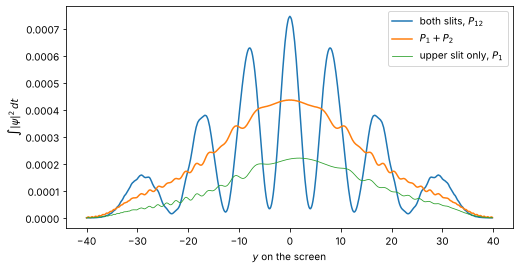

In [7]:
_, rho_1, T_1 = run(Slits([d / 2], a))
P_1 = rho_1[i_screen]
P_2 = np.roll(P_1[::-1], 1)  # mirror image y -> -y (y = 0 is at index N/2)

plt.plot(y, screen, label="both slits, $P_{12}$")
plt.plot(y, P_1 + P_2, label="$P_1 + P_2$")
plt.plot(y, P_1, lw=0.8, label="upper slit only, $P_1$")
plt.xlabel("$y$ on the screen")
plt.ylabel(r"$\int |\psi|^2\,dt$")
plt.legend()
print(f"transmitted: both slits {T_both:.4f}, one slit {T_1:.4f}, twice that {2 * T_1:.4f}")

The interference term only moves probability around: $P_{12}$ oscillates about $P_1 + P_2$, and the
total transmission through the slits, which `Flux` measures, is the sum of the two single slit
values. A detector that tells which slit the particle took would destroy the phase relation between
$\psi_1$ and $\psi_2$ and leave $P_1 + P_2$.

Things to try:

* Change the slit distance `d` or the `wavelength` and check the fringe distance $\lambda L/d$.
* Make the slits wider than the wavelength: the single slit pattern narrows and shows side maxima.
* Use more slits, e.g. `Slits([-5, 0, 5], a)`, and watch the main maxima sharpen into those of a grating.